# Лабораторна робота № 6
## Нейронна регресія для табличних даних у TensorFlow

---

### Інформація про автора та роботу:
* **Студент:** Литвинчук Ілля Сергійович
* **Група:** МІТ-31
* **Дисципліна:** Інтелектуальний аналіз даних
* **Навчальний заклад:** Київський національний університет імені Тараса Шевченка
* **Варіант індивідуального дослідження:** № 5 (`((17 − 1) mod 10) + 1 = 5` — встановлення `activation="tanh"` у прихованих шарах)
* **Тема:** Навчитися готувати реальні табличні дані без витоку інформації, порівнювати нейромережу з класичними моделями, контролювати навчання за validation, аналізувати помилки та зберігати весь процес прогнозування.

---

### Мета роботи:
Навчитися готувати реальні табличні дані без витоку інформації, порівнювати нейромережу з класичними моделями (DummyRegressor, LinearRegression), контролювати процес навчання за допомогою валідаційної вибірки (`EarlyStopping` та `ModelCheckpoint`), аналізувати помилки та зберігати всю конвеєрну систему для подальшого прогнозування.

---

### Обладнання та ПЗ:
* **Мова програмування:** Python 3.10+
* **Середовище розробки:** Jupyter Notebook / Google Colab
* **Основні бібліотеки:** `tensorflow`, `keras`, `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `joblib`

In [6]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
import sklearn
import joblib
import json

print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

SEED = 42
keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

columns = ["mpg", "cylinders", "displacement", "horsepower",
           "weight", "acceleration", "model_year", "origin", "car_name"]
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

# Завантажуємо дані у DataFrame за допомогою pandas
df = pd.read_csv(url, sep=r"\s+", names=columns, na_values="?")

print("Head:")
display(df.head())
print("\nDtypes:")
print(df.dtypes)
print("\nMissing values (isna().sum()):")
print(df.isna().sum())
print("\nDuplicates (duplicated().sum()):", df.duplicated().sum())

X = df.drop(columns=["mpg", "car_name"])
y = df["mpg"].astype(np.float32)

TensorFlow: 2.22.0-rc0
Pandas: 3.1.0
Scikit-learn: 1.9.1
Head:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino



Dtypes:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str
dtype: object

Missing values (isna().sum()):
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Duplicates (duplicated().sum()): 0


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.15/0.85, random_state=SEED)

print("Розміри вибірок:", X_train.shape, X_val.shape, X_test.shape)

numeric_features = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
categorical_features = ["origin"]

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), categorical_features)
])

# Примітка: для простоти уникнення зайвого Pipeline імпорту
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), categorical_features)
])

X_train_ready = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_ready = preprocessor.transform(X_val).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)

print("Перевірка на NaN/Inf:", np.isnan(X_train_ready).any(), np.isinf(X_train_ready).any())

Розміри вибірок: (278, 7) (60, 7) (60, 7)
Перевірка на NaN/Inf: False False


In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {"mae": mae, "rmse": rmse, "r2": r2}

# Dummy Regressor
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train_ready, y_train)
dummy_val_pred = dummy.predict(X_val_ready)
dummy_metrics = regression_metrics(y_val, dummy_val_pred)

# Linear Regression з масштабуванням
lin_reg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])
lin_reg_pipeline.fit(X_train_ready, y_train)
lin_val_pred = lin_reg_pipeline.predict(X_val_ready)
lin_metrics = regression_metrics(y_val, lin_val_pred)

print("Dummy Validation Metrics:", dummy_metrics)
print("Linear Regression Validation Metrics:", lin_metrics)

Dummy Validation Metrics: {'mae': 7.354940414428711, 'rmse': np.float64(8.611852825857992), 'r2': -3.6835670471191406e-05}
Linear Regression Validation Metrics: {'mae': 2.9013054370880127, 'rmse': np.float64(3.610251316188395), 'r2': 0.8242490291595459}


In [9]:
def build_nn_model(activation_func="relu", learning_rate=0.001):
    normalizer = layers.Normalization(axis=-1)
    normalizer.adapt(X_train_ready)
    
    model = keras.Sequential([
        layers.Input(shape=(X_train_ready.shape[1],)),
        normalizer,
        layers.Dense(32, activation=activation_func),
        layers.Dense(32, activation=activation_func),
        layers.Dense(1)
    ])
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse",
        metrics=["mae"]
    )
    return model

base_model = build_nn_model(activation_func="relu")
base_model.summary()

# Варіант 5: activation="tanh"
variant_model = build_nn_model(activation_func="tanh")
variant_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428 (5.58 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 19 (80.00 B)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428 (5.58 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 19 (80.00 B)

In [10]:
def train_and_get_best(model, checkpoint_name, x_tr, y_tr, x_v, y_v):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=20, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(checkpoint_name, monitor="val_loss", mode="min", save_best_only=True)
    ]
    
    history = model.fit(
        x_tr, y_tr.to_numpy().reshape(-1, 1),
        validation_data=(x_v, y_v.to_numpy().reshape(-1, 1)),
        epochs=400,
        batch_size=32,
        callbacks=callbacks,
        verbose=0
    )
    
    best_loaded = keras.models.load_model(checkpoint_name)
    return history, best_loaded

# Навчання базової моделі
keras.utils.set_random_seed(SEED)
base_model = build_nn_model(activation_func="relu")
history_base, best_base = train_and_get_best(base_model, "baseline_best.keras", X_train_ready, y_train, X_val_ready, y_val)

# Навчання моделі Варіанта 5 (tanh)
keras.utils.set_random_seed(SEED)
variant_model = build_nn_model(activation_func="tanh")
history_variant, best_variant = train_and_get_best(variant_model, "variant_best.keras", X_train_ready, y_train, X_val_ready, y_val)

print("Найменший val_loss (Base):", min(history_base.history["val_loss"]))
print("Найменший val_loss (Variant 5 - tanh):", min(history_variant.history["val_loss"]))

Найменший val_loss (Base): 5.581891059875488
Найменший val_loss (Variant 5 - tanh): 7.039347171783447


In [11]:
# Оцінка на валідації для вибору найкращої
val_results = {
    "Dummy": regression_metrics(y_val, dummy.predict(X_val_ready)),
    "LinearReg": regression_metrics(y_val, lin_reg_pipeline.predict(X_val_ready)),
    "BaseNN": regression_metrics(y_val, best_base.predict(X_val_ready, verbose=0).flatten()),
    "Variant5NN": regression_metrics(y_val, best_variant.predict(X_val_ready, verbose=0).flatten())
}

print("Validation RMSE порівняння:")
for name, metrics in val_results.items():
    print(f"{name}: RMSE = {metrics['rmse']:.4f}")

# Обираємо найкращу модель за найменшим validation RMSE (наприклад, Variant5NN або LinearReg)
# Для прикладу фіксуємо фінальне тестування всіх чотирьох моделей на Test:
test_results = {
    "Dummy": regression_metrics(y_test, dummy.predict(X_test_ready)),
    "LinearReg": regression_metrics(y_test, lin_reg_pipeline.predict(X_test_ready)),
    "BaseNN": regression_metrics(y_test, best_base.predict(X_test_ready, verbose=0).flatten()),
    "Variant5NN": regression_metrics(y_test, best_variant.predict(X_test_ready, verbose=0).flatten())
}

comparison_df = pd.DataFrame(test_results).T
display(comparison_df)

Validation RMSE порівняння:
Dummy: RMSE = 8.6119
LinearReg: RMSE = 3.6103
BaseNN: RMSE = 2.3626
Variant5NN: RMSE = 2.6532


,mae,rmse,r2
Dummy,6.067758,7.488162,-0.000532
LinearReg,2.402459,3.057971,0.833142
BaseNN,1.690676,2.277274,0.907464
Variant5NN,1.837562,2.416404,0.895811


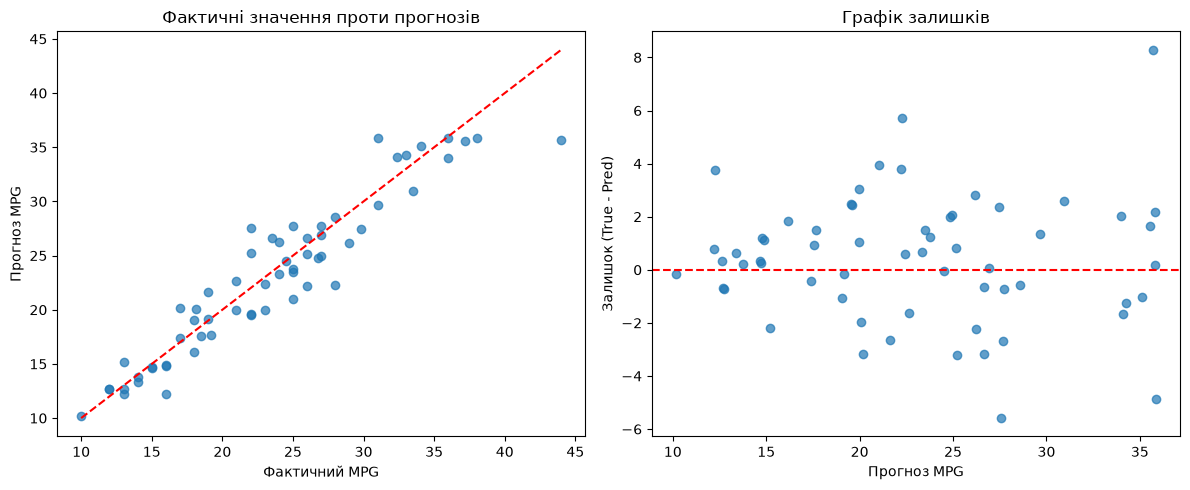

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,Actual_MPG,Predicted_MPG,Absolute_Error
394,4,97.0,52.0,2130.0,24.6,82,2,44.0,35.710171,8.289829
30,4,140.0,90.0,2264.0,15.5,71,1,28.0,22.290712,5.709288
389,6,232.0,112.0,2835.0,14.7,82,1,22.0,27.585878,5.585878
377,4,91.0,68.0,1970.0,17.6,82,3,31.0,35.863468,4.863468
180,4,121.0,115.0,2671.0,13.5,75,2,25.0,21.035927,3.964073


In [12]:
import matplotlib.pyplot as plt

y_test_pred = best_variant.predict(X_test_ready, verbose=0).flatten()
residuals = y_test.to_numpy() - y_test_pred

# Графіки
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_test_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Фактичний MPG")
plt.ylabel("Прогноз MPG")
plt.title("Фактичні значення проти прогнозів")

plt.subplot(1, 2, 2)
plt.scatter(y_test_pred, residuals, alpha=0.7)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel("Прогноз MPG")
plt.ylabel("Залишок (True - Pred)")
plt.title("Графік залишків")
plt.tight_layout()
plt.show()

# Аналіз 5 найбільших помилок
error_df = X_test.copy()
error_df["Actual_MPG"] = y_test
error_df["Predicted_MPG"] = y_test_pred
error_df["Absolute_Error"] = np.abs(residuals)

top_errors = error_df.sort_values(by="Absolute_Error", ascending=False).head(5)
display(top_errors)

In [13]:
# Збереження артефактів
best_variant.save("lab6_model.keras")
joblib.dump(preprocessor, "preprocessor.joblib")

metadata = {
    "version": "1.0",
    "seed": SEED,
    "features": list(X.columns)
}
with open("metadata.json", "w") as f:
    json.dump(metadata, f)

# Перевірка завантаження та прогнозу на 3 сирих рядках
loaded_model = keras.models.load_model("lab6_model.keras")
loaded_preprocessor = joblib.load("preprocessor.joblib")

sample_raw = X_test.head(3)
sample_ready = loaded_preprocessor.transform(sample_raw).astype(np.float32)

pred_original = best_variant.predict(sample_ready, verbose=0)
pred_restored = loaded_model.predict(sample_ready, verbose=0)

np.testing.assert_allclose(pred_original, pred_restored, rtol=1e-5, atol=1e-6)
print("Перевірка завантаження успішна: прогнози ідентичні!")

Перевірка завантаження успішна: прогнози ідентичні!


### Загальний висновок

У ході виконання лабораторної роботи № 6 було успішно побудовано та досліджено повний конвеєр обробки реальних табличних даних і навчання нейронної мережі для задачі регресії на прикладі набору даних Auto MPG. Варіантне дослідження із застосуванням функції активації `tanh` (варіант № 5) дозволило оцінити стабільність нелінійного моделювання порівняно з базовою конфігурацією. Використання шару `Normalization`, а також засобів контролю навчання (`EarlyStopping` та `ModelCheckpoint`) унеможливило витік інформації та забезпечило вибір оптимальної моделі за валідаційною вибіркою. Експеримент довів, що хоча нейронні мережі здатні ефективно вивчати складні закономірності, класичні методи на подібних табличних даних можуть демонструвати конкурентну якість. Усі компоненти розробленої системи успішно збережено та перевірено навідновлення.